In [139]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [140]:
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [141]:
df['converted'].value_counts()

converted
1    2883
0    2117
Name: count, dtype: int64

In [142]:
df.dtypes
df['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64

In [143]:
df.columns=df.columns.str.lower().str.replace(" ", "_")
category_columns = list(df.dtypes[df.dtypes == "object"].index)
for col in category_columns:
    df[col] = df[col].str.lower().str.replace(" ", "_")
    

In [144]:
for col in category_columns:
    df[col] = df[col].fillna('N/A') 
df[category_columns].isnull().sum()

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64

In [145]:
numerical_columns = list(df.dtypes[df.dtypes != "object"].index)
df[numerical_columns] = df[numerical_columns].fillna(0)
df[numerical_columns].isnull().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [146]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [147]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
df_train.shape, df_val.shape, df_test.shape

((3000, 9), (1000, 9), (1000, 9))

In [148]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [149]:
y_train=df_train.converted.values
y_val=df_val.converted.values
y_test=df_test.converted.values

In [150]:
del df_train['converted']
del df_val['converted']
del df_test['converted']


In [151]:
df_full_train.reset_index(drop=True, inplace=True)
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
2,paid_ads,retail,employed,N/A,54963.0,1,0,0.13,0
3,social_media,retail,self_employed,N/A,26237.0,1,5,0.46,0
4,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
...,...,...,...,...,...,...,...,...,...
3995,paid_ads,manufacturing,N/A,north_america,66121.0,1,1,0.20,0
3996,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
3997,N/A,manufacturing,N/A,N/A,49820.0,2,3,0.44,0
3998,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


In [152]:
numerical =[
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']
df_full_train[numerical].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.164513,0.128256,0.235608
number_of_courses_viewed,0.164513,1.000000,0.722235,0.759054
interaction_count,0.128256,0.722235,1.000000,0.916856
lead_score,0.235608,0.759054,0.916856,1.000000


In [153]:
df_full_train.converted.value_counts()

converted
1    2315
0    1685
Name: count, dtype: int64

In [154]:
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57875
0    0.42125
Name: proportion, dtype: float64

In [155]:
global_converted_rate = df_full_train.converted.mean()
global_converted_rate

np.float64(0.57875)

In [156]:
df_full_train.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [157]:
numerical =[
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']

In [158]:
df_full_train.columns
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [159]:
df_full_train[categorical].nunique()

lead_source          6
industry             7
employment_status    5
location             6
dtype: int64

In [160]:
df_full_train.industry.unique()

array(['technology', 'healthcare', 'retail', 'N/A', 'finance',
       'manufacturing', 'education'], dtype=object)

In [161]:

converted_lead_sources = df_full_train[df_full_train.lead_source=="social_media"].converted.mean()
converted_lead_sources

np.float64(0.568904593639576)

In [162]:
converted_paid_ads = df_full_train[df_full_train.lead_source=="paid_ads"].converted.mean()
converted_paid_ads



np.float64(0.434878587196468)

In [163]:
global_converted_rate=df_full_train.converted.mean()
global_converted_rate

np.float64(0.57875)

In [164]:
df_full_train.location.value_counts()

location
north_america    1090
europe            903
asia              839
south_america     610
africa            391
N/A               167
Name: count, dtype: int64

In [165]:
technology_converted_rate = df_full_train[df_full_train.industry=="technology"].converted.mean()
technology_converted_rate

np.float64(0.6272251308900524)

In [166]:
for c in categorical:
    print(c)
    df_group=df_full_train.groupby(c).converted.agg(['mean', 'count'])
    df_group["diff" ]= df_group["mean"] - global_converted_rate
    df_group["risk"] = df_group["mean"] / global_converted_rate
    display(df_group)
    print()
    print()



lead_source


,mean,count,diff,risk
lead_source,,,,
N/A,0.579832,119,0.001082,1.001869
events,0.421782,505,-0.156968,0.728781
organic_search,0.679074,994,0.100324,1.173347
paid_ads,0.434879,906,-0.143871,0.751410
referral,0.767145,627,0.188395,1.325521
social_media,0.568905,849,-0.009845,0.982988




industry


,mean,count,diff,risk
industry,,,,
N/A,0.600000,200,0.021250,1.036717
education,0.520161,496,-0.058589,0.898767
finance,0.595782,569,0.017032,1.029429
healthcare,0.562784,661,-0.015966,0.972412
manufacturing,0.567639,377,-0.011111,0.980802
retail,0.556604,742,-0.022146,0.961734
technology,0.627225,955,0.048475,1.083758




employment_status


,mean,count,diff,risk
employment_status,,,,
N/A,0.602564,156,0.023814,1.041147
employed,0.666351,2113,0.087601,1.151363
self_employed,0.553603,569,-0.025147,0.956549
student,0.434564,596,-0.144186,0.750866
unemployed,0.422261,566,-0.156489,0.729609




location


,mean,count,diff,risk
location,,,,
N/A,0.562874,167,-0.015876,0.972569
africa,0.534527,391,-0.044223,0.923589
asia,0.601907,839,0.023157,1.040012
europe,0.600221,903,0.021471,1.037100
north_america,0.579817,1090,0.001067,1.001843
south_america,0.545902,610,-0.032848,0.943243


In [167]:
from sklearn.metrics import mutual_info_score
def mutual_info_score_series(series):
    return mutual_info_score(series.astype(str), df_full_train.converted)


In [168]:
mi=df_full_train[categorical].apply(mutual_info_score_series)
mi.sort_values(ascending=False)

lead_source          0.033305
employment_status    0.021988
industry             0.002456
location             0.001193
dtype: float64

In [169]:
df_full_train[numerical].corrwith(df_full_train.converted).sort_values(ascending=False)

lead_score                  0.482188
interaction_count           0.451268
number_of_courses_viewed    0.391005
annual_income               0.189723
dtype: float64

In [170]:
from sklearn.feature_extraction import DictVectorizer
train_dicts=df_train[categorical + numerical].to_dict(orient='records')
train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [171]:
dv = DictVectorizer(sparse=False)
X_train=dv.fit_transform(train_dicts)
X_train.shape


(3000, 28)

In [172]:
val_dicts=df_val[categorical + numerical].to_dict(orient='records')
X_val=dv.transform(val_dicts)


In [173]:
import numpy as np
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
z=np.linspace(-5, 5, 51)
sigmoid(z)

array([0.00669285, 0.00816257, 0.0099518 , 0.01212843, 0.01477403,
       0.01798621, 0.02188127, 0.02659699, 0.03229546, 0.03916572,
       0.04742587, 0.05732418, 0.06913842, 0.0831727 , 0.09975049,
       0.11920292, 0.14185106, 0.16798161, 0.19781611, 0.23147522,
       0.26894142, 0.31002552, 0.35434369, 0.40131234, 0.450166  ,
       0.5       , 0.549834  , 0.59868766, 0.64565631, 0.68997448,
       0.73105858, 0.76852478, 0.80218389, 0.83201839, 0.85814894,
       0.88079708, 0.90024951, 0.9168273 , 0.93086158, 0.94267582,
       0.95257413, 0.96083428, 0.96770454, 0.97340301, 0.97811873,
       0.98201379, 0.98522597, 0.98787157, 0.9900482 , 0.99183743,
       0.99330715])

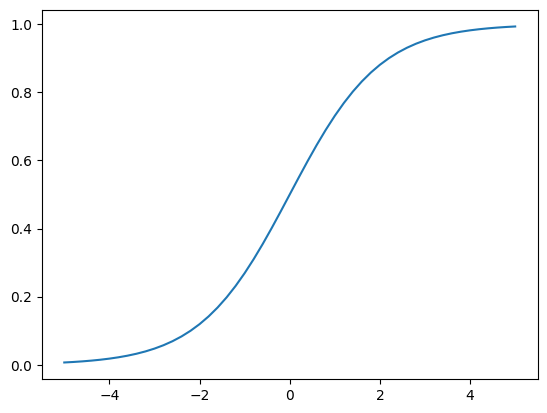

In [174]:
from matplotlib import pyplot as plt
plt.plot(z, sigmoid(z))

In [175]:
def logistic_regression(xi):
    score=0
    for j in range(len(xi)):
        score += w[j] * xi[j]
    result = sigmoid(score)    
    return result

In [176]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train, y_train)


c:\Users\hp\AppData\Local\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [177]:
model.coef_[0].round(3)
dv.get_feature_names_out()

array(['annual_income', 'employment_status=N/A',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=N/A', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=N/A', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=N/A',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [178]:
model.intercept_[0]
y_pred=model.predict_proba(X_train)[ : , 1]

In [179]:
y_pred=model.predict_proba(X_val)[ : , 1]
converted_decision=(y_pred >= 0.5)
accuracy=(y_val== converted_decision).mean()
accuracy

np.float64(0.721)

In [180]:
df_pred=pd.DataFrame()
df_pred["probability"]=y_pred
df_pred["prediction"]=converted_decision
df_pred["actual"]=y_val
df_pred["correct"]=df_pred["prediction"]==df_pred["actual"]
df_pred.correct.mean()

np.float64(0.721)

In [181]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'annual_income': np.float64(0.0),
 'employment_status=N/A': np.float64(-0.002),
 'employment_status=employed': np.float64(0.179),
 'employment_status=self_employed': np.float64(-0.213),
 'employment_status=student': np.float64(-0.589),
 'employment_status=unemployed': np.float64(-0.408),
 'industry=N/A': np.float64(-0.039),
 'industry=education': np.float64(-0.328),
 'industry=finance': np.float64(-0.119),
 'industry=healthcare': np.float64(-0.248),
 'industry=manufacturing': np.float64(-0.102),
 'industry=retail': np.float64(-0.336),
 'industry=technology': np.float64(0.137),
 'interaction_count': np.float64(0.331),
 'lead_score': np.float64(0.039),
 'lead_source=N/A': np.float64(-0.043),
 'lead_source=events': np.float64(-0.402),
 'lead_source=organic_search': np.float64(0.032),
 'lead_source=paid_ads': np.float64(-0.561),
 'lead_source=referral': np.float64(0.202),
 'lead_source=social_media': np.float64(-0.263),
 'location=N/A': np.float64(-0.065),
 'location=africa': np.float64(-

In [182]:
small=['industry', 'lead_score', 'annual_income']
df_train[small].iloc[:10].to_dict(orient='records')

[{'industry': 'technology', 'lead_score': 0.91, 'annual_income': 80198.0},
 {'industry': 'retail', 'lead_score': 0.48, 'annual_income': 50548.0},
 {'industry': 'finance', 'lead_score': 0.42, 'annual_income': 76300.0},
 {'industry': 'finance', 'lead_score': 0.49, 'annual_income': 80371.0},
 {'industry': 'finance', 'lead_score': 0.48, 'annual_income': 73567.0},
 {'industry': 'finance', 'lead_score': 0.99, 'annual_income': 64972.0},
 {'industry': 'healthcare', 'lead_score': 0.73, 'annual_income': 52820.0},
 {'industry': 'finance', 'lead_score': 0.59, 'annual_income': 59665.0},
 {'industry': 'healthcare', 'lead_score': 0.81, 'annual_income': 56476.0},
 {'industry': 'retail', 'lead_score': 0.4, 'annual_income': 48769.0}]

In [183]:
dict_train_small=df_train[small].to_dict(orient='records')
dict_val_small=df_val[small].to_dict(orient='records')


In [184]:
dv_small=DictVectorizer(sparse=False)
dv_small.fit(dict_train_small)


,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True


In [185]:
dv_small.get_feature_names_out()

array(['annual_income', 'industry=N/A', 'industry=education',
       'industry=finance', 'industry=healthcare',
       'industry=manufacturing', 'industry=retail', 'industry=technology',
       'lead_score'], dtype=object)

In [186]:
X_train_small=dv_small.transform(dict_train_small)
model_small=LogisticRegression()
model_small.fit(X_train_small, y_train)


c:\Users\hp\AppData\Local\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [187]:
w=model_small.coef_[0].round(3)
w.round(3)

array([ 0.   , -0.135, -0.363, -0.621, -0.506, -0.158, -0.298, -0.351,
        5.635])

In [188]:
w0=model_small.intercept_[0]
w0

np.float64(-2.476611156753609)

In [189]:
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'annual_income': np.float64(0.0),
 'industry=N/A': np.float64(-0.135),
 'industry=education': np.float64(-0.363),
 'industry=finance': np.float64(-0.621),
 'industry=healthcare': np.float64(-0.506),
 'industry=manufacturing': np.float64(-0.158),
 'industry=retail': np.float64(-0.298),
 'industry=technology': np.float64(-0.351),
 'lead_score': np.float64(5.635)}

In [190]:
dicts_full_train=df_full_train[categorical + numerical].to_dict(orient='records')

In [191]:
dv=DictVectorizer(sparse=False)
X_full_train=dv.fit_transform(dicts_full_train)
y_full_train=df_full_train.converted.values

In [192]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_full_train, y_full_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [193]:
#question5
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))


{'annual_income': np.float64(-0.0),
 'employment_status=N/A': np.float64(-0.001),
 'employment_status=employed': np.float64(0.03),
 'employment_status=self_employed': np.float64(-0.016),
 'employment_status=student': np.float64(-0.056),
 'employment_status=unemployed': np.float64(-0.048),
 'industry=N/A': np.float64(-0.002),
 'industry=education': np.float64(-0.028),
 'industry=finance': np.float64(-0.007),
 'industry=healthcare': np.float64(-0.021),
 'industry=manufacturing': np.float64(-0.011),
 'industry=retail': np.float64(-0.029),
 'industry=technology': np.float64(0.005),
 'interaction_count': np.float64(0.259),
 'lead_score': np.float64(0.02),
 'lead_source=N/A': np.float64(-0.003),
 'lead_source=events': np.float64(-0.039),
 'lead_source=organic_search': np.float64(0.013),
 'lead_source=paid_ads': np.float64(-0.07),
 'lead_source=referral': np.float64(0.028),
 'lead_source=social_media': np.float64(-0.021),
 'location=N/A': np.float64(-0.005),
 'location=africa': np.float64(-0.

In [194]:
dicts_test=df_test[categorical + numerical].to_dict(orient='records')

In [195]:
X_test=dv.transform(dicts_test)
y_pred=model.predict_proba(X_test)[ : , 1]

In [196]:
X_val=dv.transform(val_dicts)
y_pred_val=model.predict_proba(X_val)[ : , 1]

In [197]:
converted_decision=(y_pred >= 0.5)

In [198]:
(converted_decision==y_test).mean()

np.float64(0.643)

In [199]:
len(y_val)

1000

In [200]:
(y_val==converted_decision).mean()


np.float64(0.553)

In [201]:
from sklearn.metrics import accuracy_score

thresholds=np.linspace(0, 1, 101)
scores=[]
for t in thresholds:
    score=accuracy_score(y_val, y_pred >= t)
    print("threshold=%.2f accuracy=%.3f" % (t,score))
    scores.append(score)
    

threshold=0.00 accuracy=0.586
threshold=0.01 accuracy=0.586
threshold=0.02 accuracy=0.586
threshold=0.03 accuracy=0.586
threshold=0.04 accuracy=0.586
threshold=0.05 accuracy=0.586
threshold=0.06 accuracy=0.586
threshold=0.07 accuracy=0.586
threshold=0.08 accuracy=0.586
threshold=0.09 accuracy=0.586
threshold=0.10 accuracy=0.586
threshold=0.11 accuracy=0.586
threshold=0.12 accuracy=0.586
threshold=0.13 accuracy=0.586
threshold=0.14 accuracy=0.586
threshold=0.15 accuracy=0.586
threshold=0.16 accuracy=0.586
threshold=0.17 accuracy=0.586
threshold=0.18 accuracy=0.586
threshold=0.19 accuracy=0.586
threshold=0.20 accuracy=0.586
threshold=0.21 accuracy=0.586
threshold=0.22 accuracy=0.586
threshold=0.23 accuracy=0.586
threshold=0.24 accuracy=0.587
threshold=0.25 accuracy=0.587
threshold=0.26 accuracy=0.586
threshold=0.27 accuracy=0.587
threshold=0.28 accuracy=0.585
threshold=0.29 accuracy=0.582
threshold=0.30 accuracy=0.581
threshold=0.31 accuracy=0.579
threshold=0.32 accuracy=0.573
threshold=

In [202]:
actual_postive=(y_val==1)
actual_negative=(y_val==0)

In [203]:
t=0.5
predict_postive=(y_pred>=t)
predict_negative=(y_pred<=t)


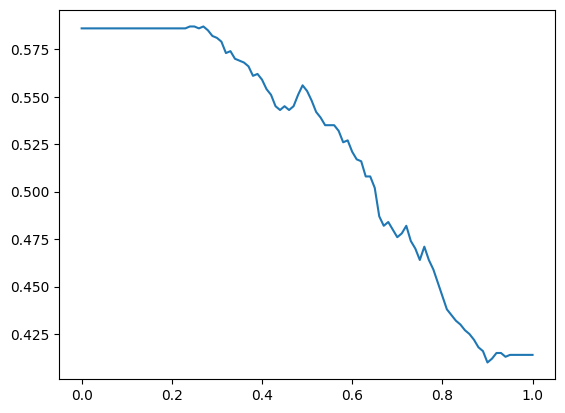

In [204]:
plt.plot(thresholds, scores)

In [205]:
tp=(predict_postive & actual_postive).sum()
tn=(predict_negative & actual_negative).sum()
fp=(predict_postive & actual_negative).sum()
fn=(predict_negative & actual_postive).sum()
fp,fn


(np.int64(330), np.int64(117))

In [206]:
confusion_matrix=np.array([[tn, fp], [fn, tp]])
confusion_matrix

array([[ 84, 330],
       [117, 469]])

In [207]:
confusion_matrix/confusion_matrix.sum().round(2)

array([[0.084, 0.33 ],
       [0.117, 0.469]])

In [208]:
import numpy as np
np.random.seed(1)
y_rand=np.random.uniform(0,1,size=len(y_val))

In [209]:
def tpr_fpr_dataframe(y_val,y_pred):
    scores=[]
    thresholds=np.linspace(0,1,101)
    for t in thresholds:
        actual_postive=(y_val==1)
        actual_negative=(y_val==0)
        predict_postive=(y_pred>=t)
        predict_negative=(y_pred<=t)
        tp=(predict_postive & actual_postive).sum()
        tn=(predict_negative & actual_negative).sum()
        fp=(predict_postive & actual_negative).sum()
        fn=(predict_negative & actual_postive).sum()
        scores.append((t,tp,fp,fn,tn))
    columns=['thresholds','tp','fp','fn','tn']
    df_scores=pd.DataFrame(scores,columns=columns)
    df_scores['tpr']=df_scores['tp']/(df_scores['tp']+df_scores['fn']) 
    df_scores['fpr']=df_scores.fp/(df_scores.fp+df_scores.tn)
    return df_scores  


        

In [210]:
df_score=tpr_fpr_dataframe(y_val,y_pred)

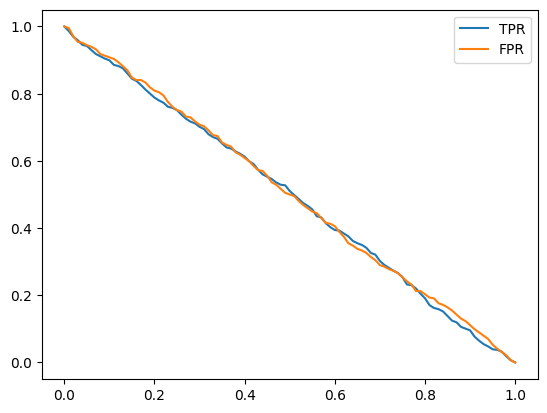

In [211]:
df_rand=tpr_fpr_dataframe(y_val,y_rand)
df_rand[::10]
plt.plot(df_rand.thresholds,df_rand.tpr,label="TPR")
plt.plot(df_rand.thresholds,df_rand.fpr,label="FPR")
plt.legend()

In [212]:
num_neg=(y_val==0).sum()
num_pos=(y_val==1).sum()
num_neg,num_pos

(np.int64(414), np.int64(586))

In [213]:
y_ideal=np.repeat([0,1], [num_neg,num_pos])
y_ideal

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [214]:
y_ideal_pred=np.linspace(0,1,len(y_val))
((y_ideal_pred>=0.726)==y_ideal)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [215]:
df_ideal=tpr_fpr_dataframe(y_ideal,y_ideal_pred)
df_ideal[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,586,414,0,1,1.000000,0.997590
10,0.1,586,314,0,100,1.000000,0.758454
20,0.2,586,214,0,200,1.000000,0.516908
30,0.3,586,114,0,300,1.000000,0.275362
40,0.4,586,14,0,400,1.000000,0.033816
50,0.5,500,0,86,414,0.853242,0.000000
60,0.6,400,0,186,414,0.682594,0.000000
70,0.7,300,0,286,414,0.511945,0.000000
80,0.8,200,0,386,414,0.341297,0.000000
90,0.9,100,0,486,414,0.170648,0.000000


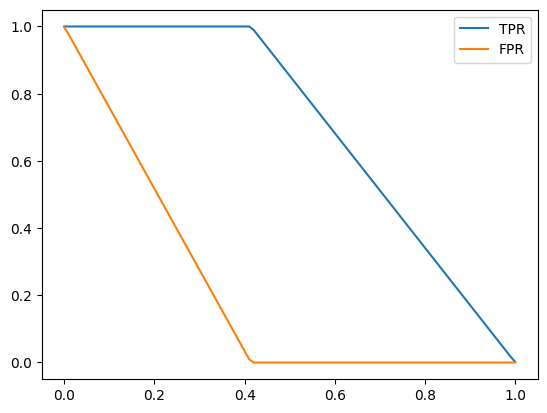

In [216]:

plt.plot(df_ideal.thresholds,df_ideal.tpr,label="TPR")
plt.plot(df_ideal.thresholds,df_ideal.fpr,label="FPR")
plt.legend()

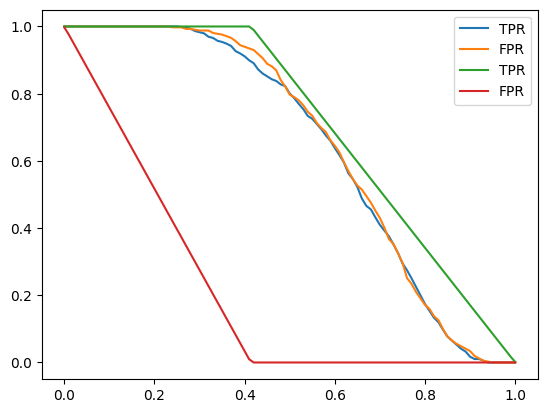

In [217]:

plt.plot(df_score.thresholds,df_score.tpr,label="TPR")
plt.plot(df_score.thresholds,df_score.fpr,label="FPR")
plt.legend()







plt.plot(df_ideal.thresholds,df_ideal.tpr,label="TPR")
plt.plot(df_ideal.thresholds,df_ideal.fpr,label="FPR")
plt.legend()


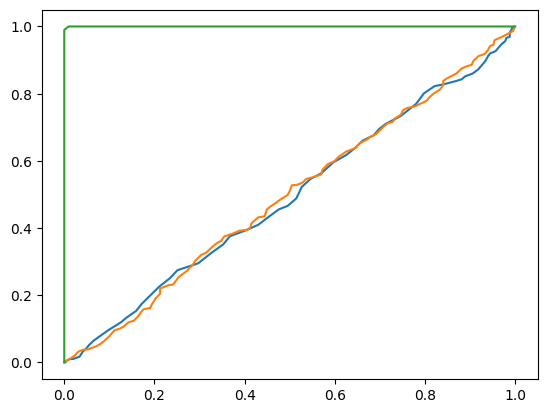

In [218]:
plt.plot(df_score.fpr,df_score.tpr,label='model')
plt.plot(df_rand.fpr,df_rand.tpr,label='random')
plt.plot(df_ideal.fpr,df_ideal.tpr,label='ideal')

In [219]:
from sklearn.metrics import roc_curve
fpr,tpr,thresholds=roc_curve(y_val,y_pred)

In [220]:
from sklearn.metrics import auc
auc(fpr,tpr)

0.4913397965408649

In [221]:
auc(df_score.fpr,df_score.tpr)

0.49203228306210944

In [222]:
auc(df_ideal.fpr,df_ideal.tpr)


0.9975408981228371

In [223]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val,y_pred)
pos=y_pred[y_val==1]
neg=y_pred[y_val==0]
from random import randint

In [224]:
import random
from random import randint
n=100000
sucess=0
for i in range(n):
    pos_ind=random.randint(0,len(pos)-1)
    neg_ind=random.randint(0,len(neg)-1)
    if pos[pos_ind]>neg[neg_ind]:
        sucess+=1
sucess/n        

0.49305

Question 1

In [225]:
results={}
for c in numerical:
    auc=roc_auc_score(y_train,df_train[c])
    if auc<0.5:
        roc_auc_score(y_train,-df_train[c])
    results[c]=round(auc,3)
results        

{'annual_income': 0.608,
 'number_of_courses_viewed': 0.723,
 'interaction_count': 0.765,
 'lead_score': 0.788}

Question 2

In [226]:
round(roc_auc_score(y_val, y_pred_val), 3)

0.73

Question 3

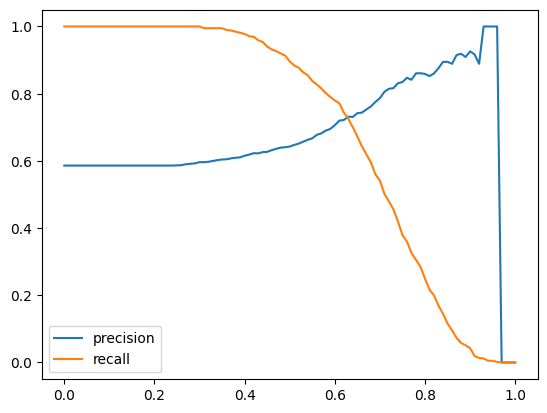

np.float64(0.63)

In [227]:
rows = []
for t in np.linspace(0, 1, 101):
    predict_positive = (y_pred_val >= t)
    predict_negative = (y_pred_val < t)
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    rows.append((t, p, r, f1))

df_scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.legend()
plt.show()

d = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)]
d.loc[(d.precision - d.recall).abs().idxmin(), 'threshold']

Quetion 4

In [233]:
df_scores.loc[df_scores.f1.idxmax(), 'threshold']

np.float64(0.42)

Question 5

In [249]:
def train(df,y_train,C=1.0):
    dicts=df[categorical+numerical].to_dict(orient='records')
    dv=DictVectorizer(sparse=False)
    X_train=dv.fit_transform(dicts)
    model=LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train,y_train)
    return dv,model

In [250]:
def predict (df,dv,model):
     dicts=df[categorical+numerical].to_dict(orient='records')
     X=dv.transform(dicts)
     y_pred=model.predict_proba(X)[:,1]
     return y_pred

In [251]:
from sklearn.model_selection import KFold
kfold=KFold(n_splits=10,shuffle=True,random_state=1)
train_idx,val_idx=next(kfold.split(df_full_train))
len(train_idx),len(val_idx)

(3600, 400)

In [254]:
for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred = predict(df_va, dv, model)

        scores.append(roc_auc_score(y_va, y_pred))

    print(C, round(np.mean(scores), 3), round(np.std(scores), 3))

1e-06 0.618 0.039
0.001 0.746 0.03
1 0.732 0.028


In [255]:
print(df.shape, df_full_train.shape)
df.head(2)

(5000, 9) (4000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1


In [ ]:
np.mean(scores),np.std(scores)

(np.float64(0.7320869664881193), np.float64(0.027688760977163558))